In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [6]:
import os
print(os.getcwd())

C:\Users\Dell\ADS


In [7]:
print(os.listdir())

['.ipynb_checkpoints', 'case_study2.ipynb', 'data.ipynb', 'dataset', 'minmax.pdf', 'tomato_dataset.ipynb', 'Untitled.ipynb', 'Untitled1.ipynb']


In [11]:
dataset_path = r"C:\Users\Dell\ADS\dataset\train"
print("Dataset path:", dataset_path)
print("Exists:", os.path.exists(dataset_path))

Dataset path: C:\Users\Dell\ADS\dataset\train
Exists: True


In [12]:
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of classes:", len(classes))
print("\nDisease classes:")

for i, class_name in enumerate(classes):
    print(i + 1, class_name)

Number of classes: 11

Disease classes:
1 Bacterial_spot
2 Early_blight
3 Late_blight
4 Leaf_Mold
5 Septoria_leaf_spot
6 Spider_mites Two-spotted_spider_mite
7 Target_Spot
8 Tomato_Yellow_Leaf_Curl_Virus
9 Tomato_mosaic_virus
10 healthy
11 powdery_mildew


In [13]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

class_counts = {}

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    
    count = sum(
        1 for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    )
    
    class_counts[class_name] = count

for class_name, count in class_counts.items():
    print(f"{class_name}: {count} images")

Bacterial_spot: 2826 images
Early_blight: 2455 images
Late_blight: 3113 images
Leaf_Mold: 2754 images
Septoria_leaf_spot: 2882 images
Spider_mites Two-spotted_spider_mite: 1747 images
Target_Spot: 1827 images
Tomato_Yellow_Leaf_Curl_Virus: 2036 images
Tomato_mosaic_virus: 2153 images
healthy: 3051 images
powdery_mildew: 1004 images


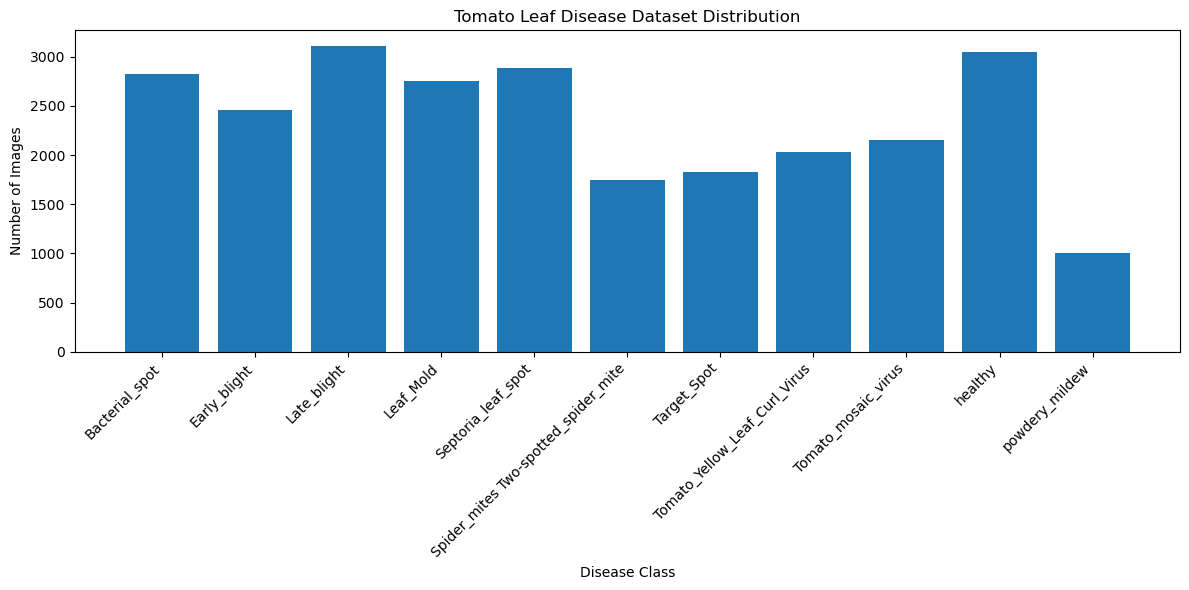

In [14]:
plt.figure(figsize=(12, 6))

plt.bar(class_counts.keys(), class_counts.values())

plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.title("Tomato Leaf Disease Dataset Distribution")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

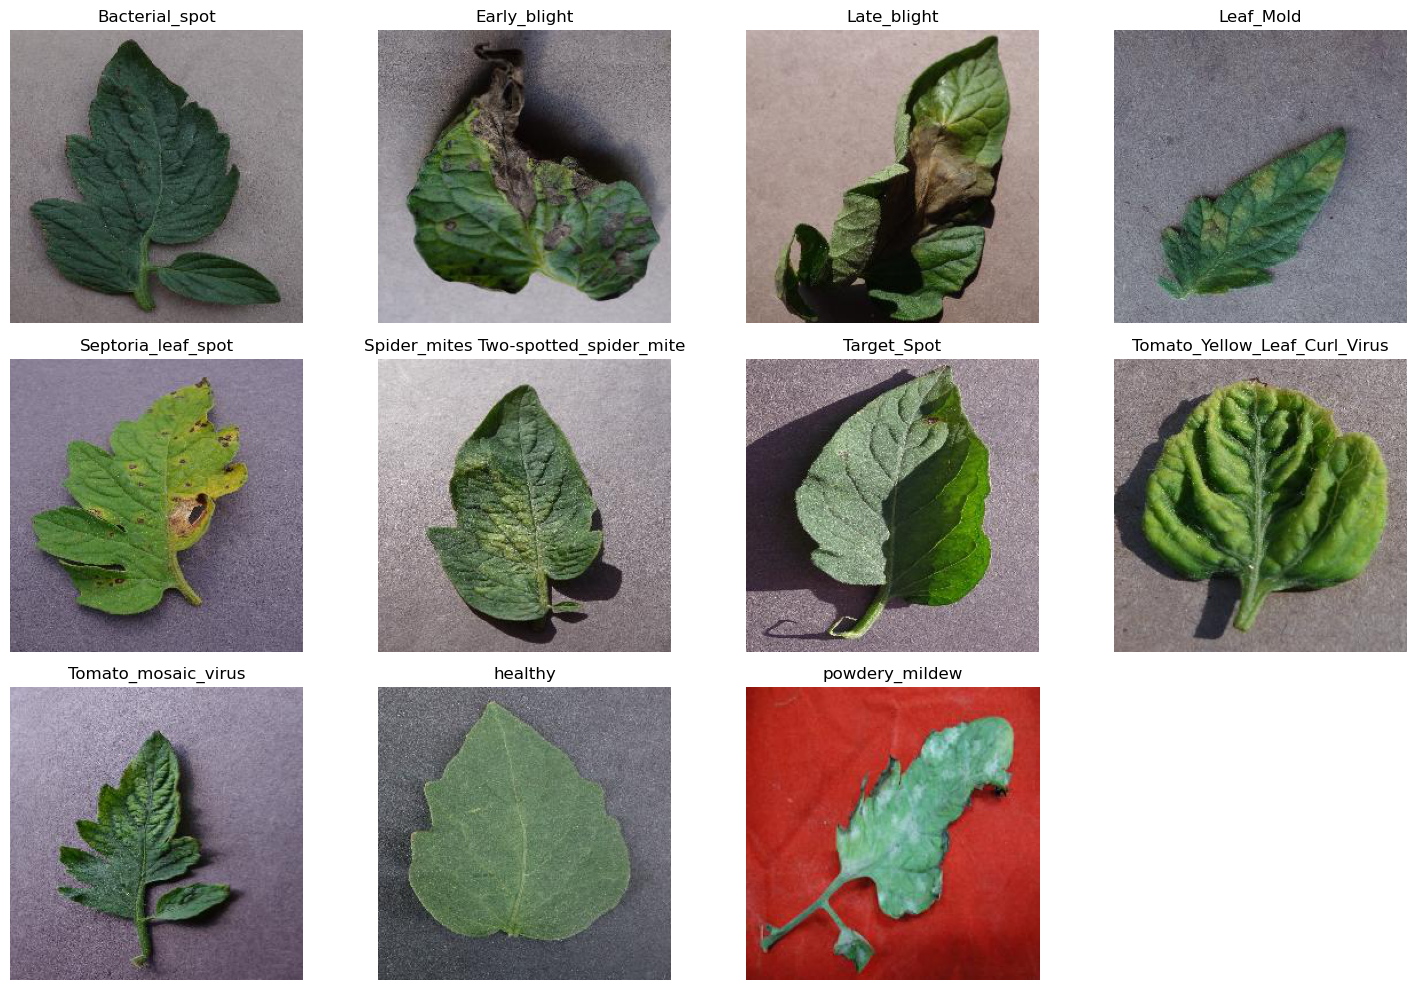

In [15]:
plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):
    
    class_path = os.path.join(dataset_path, class_name)
    
    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    ]
    
    if len(image_files) > 0:
        image_path = os.path.join(class_path, image_files[0])
        
        image = plt.imread(image_path)
        
        plt.subplot(3, 4, i + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [17]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("Dataset loaded successfully!")

Found 25848 files belonging to 11 classes.
Using 18094 files for training.
Found 25848 files belonging to 11 classes.
Using 7754 files for validation.
Dataset loaded successfully!


In [18]:
temp_batches = tf.data.experimental.cardinality(temp_ds)

val_size = temp_batches // 2

val_ds = temp_ds.take(val_size)
test_ds = temp_ds.skip(val_size)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 566
Validation batches: 121
Testing batches: 122


In [19]:
class_names = train_ds.class_names

print("Classes:")
for i, class_name in enumerate(class_names):
    print(i, ":", class_name)

print("\nNumber of classes:", len(class_names))

Classes:
0 : Bacterial_spot
1 : Early_blight
2 : Late_blight
3 : Leaf_Mold
4 : Septoria_leaf_spot
5 : Spider_mites Two-spotted_spider_mite
6 : Target_Spot
7 : Tomato_Yellow_Leaf_Curl_Virus
8 : Tomato_mosaic_virus
9 : healthy
10 : powdery_mildew

Number of classes: 11


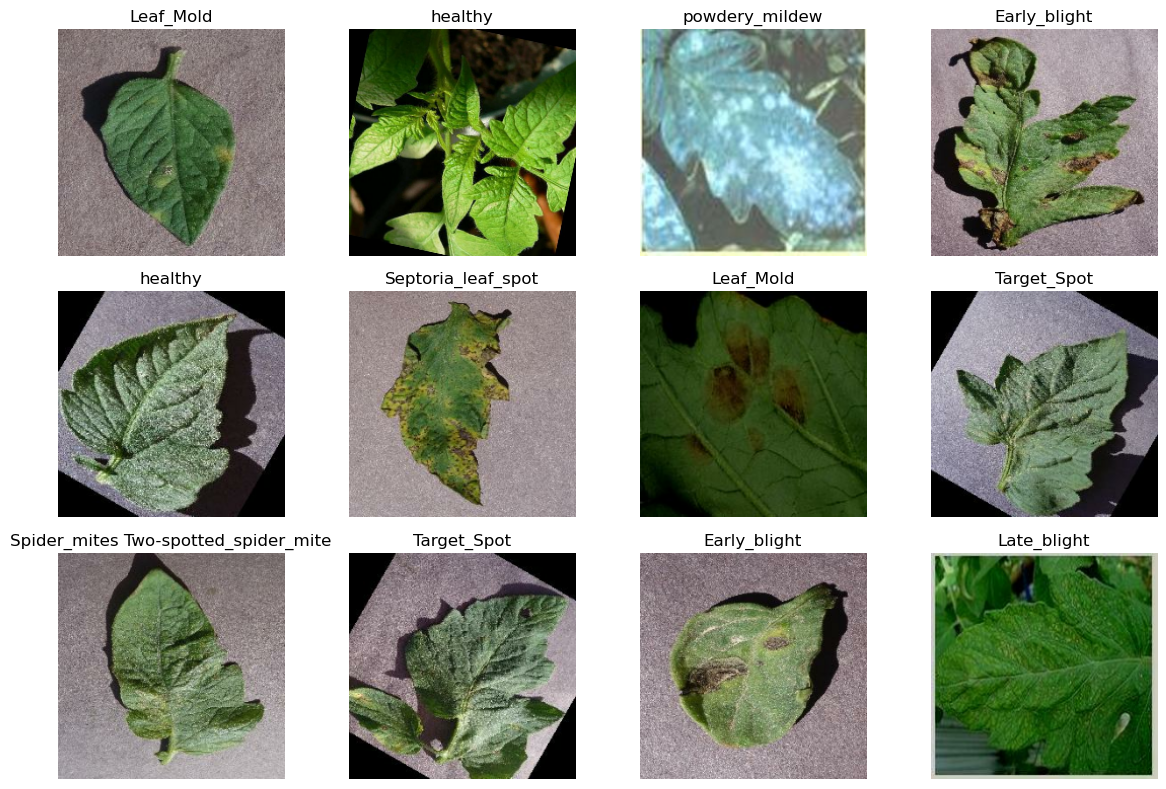

In [21]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Dataset preprocessing setup completed!")

Dataset preprocessing setup completed!


In [23]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data augmentation created!")

Data augmentation created!


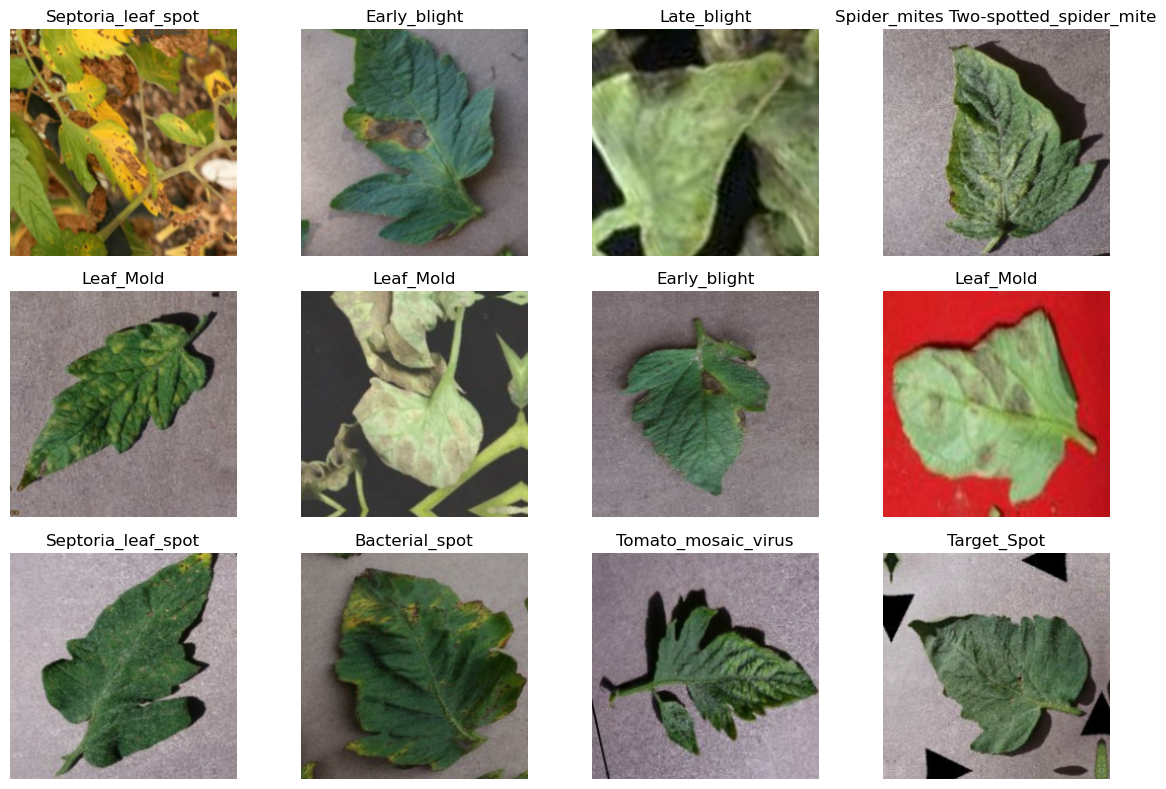

In [24]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    augmented_images = data_augmentation(images)
    
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(augmented_images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
normalization_layer = layers.Rescaling(1./255)

print("Normalization layer created!")

Normalization layer created!


In [26]:
model = keras.Sequential([
    
    # Data preprocessing
    data_augmentation,
    normalization_layer,

    # Convolution Layer 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    # Convolution Layer 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    # Convolution Layer 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    # Convert feature maps into one-dimensional data
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation="relu"),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(len(class_names), activation="softmax")
])

print("CNN model created!")

CNN model created!


In [27]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [28]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (32, 224, 224, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (32, 224, 224, 3)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (32, 222, 222, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (32, 111, 111, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (32, 109, 109, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (32, 54, 54, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (32, 52, 52, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (32, 26, 26, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (32, 86528)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (32, 128)                   │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (32, 128)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (32, 11)                    │           1,419 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,170,379 (42.61 MB)

 Trainable params: 11,170,379 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

print("CNN training completed!")

Epoch 1/10


C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


566/566 ━━━━━━━━━━━━━━━━━━━━ 1468s 3s/step - accuracy: 0.3884 - loss: 1.7456 - val_accuracy: 0.5819 - val_loss: 1.1589
Epoch 2/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1222s 2s/step - accuracy: 0.5813 - loss: 1.2007 - val_accuracy: 0.6896 - val_loss: 0.8935
Epoch 3/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1240s 2s/step - accuracy: 0.6368 - loss: 1.0380 - val_accuracy: 0.7216 - val_loss: 0.7809
Epoch 4/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1207s 2s/step - accuracy: 0.6690 - loss: 0.9457 - val_accuracy: 0.7732 - val_loss: 0.6287
Epoch 5/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1176s 2s/step - accuracy: 0.6913 - loss: 0.8822 - val_accuracy: 0.7712 - val_loss: 0.6558
Epoch 6/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1183s 2s/step - accuracy: 0.7075 - loss: 0.8354 - val_accuracy: 0.7898 - val_loss: 0.5945
Epoch 7/10
566/566 ━━━━━━━━━━━━━━━━━━━━ 1197s 2s/step - accuracy: 0.7266 - loss: 0.7768 - val_accuracy: 0.7433 - val_loss: 0.7222
Epoch 8/10
226/566 ━━━━━━━━━━━━━━━━━━━━ 11:26 2s/step - accuracy: 0.7373 - loss: 0.7397